# Spot transit: $T_s$ and Dumusque bisector $\times (a + b\mu)$

In [34]:
import os
os.environ.setdefault('KMP_WARNINGS', '0')
import copy
import numpy as np
import matplotlib.pyplot as plt

from sunsim import *
from sunsim import local_path

## Parameters

In [35]:
rotation_period = 24.47            # [days]
stellar_radius = 1
inclination = 0
differential_rotation = SOLAR_DIFFERENTIAL_ROTATION
T_quiet = 5770                     # [K]

spot_dTs = [300, 600, 1100]        # [K] T_quiet - T_spot
mu_scalings = {'Dumusque (1, 0)': (1, 0), 'Dumusque (0, 1)': (0, 1), 'Dumusque (0, 0.5)': (0, 0.5)}
spot = [active_region('sp', 10, 90, 180)]       # radius 10 deg, equator

time = np.linspace(0, rotation_period, 100)
N_rings_phot = 30
N_rings_ccf = 30

## Spectra

In [36]:
flux_quiet = np.load(str(local_path('muram_spectra') / 'av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_quiet_low = np.load(str(local_path('muram_lowres_spectra') / 'av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy'), allow_pickle=True).item()
flux_fc = np.load(str(local_path('muram_spectra') / 'av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_fc_low = np.load(str(local_path('muram_lowres_spectra') / 'av_solar_faculae_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy'), allow_pickle=True).item()
flux_sp_raw = np.load(str(local_path('muram_spot_spectra') / 'av_solar_ssd_10_mu_angles_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_sp_low_raw = np.load(str(local_path('muram_spot_spectra') / 'av_solar_ssd_10_mu_angles_PHOENIX_low_res_specint_grid.npy'), allow_pickle=True).item()

for mu in flux_sp_low_raw:
    conv = (1e-8 * flux_sp_low_raw[mu]['wav']**2 * 2.99792458e10) / 1e12
    flux_sp_low_raw[mu]['intensity'] /= conv
    flux_quiet_low[mu]['intensity'] /= conv
    flux_fc_low[mu]['intensity'] /= conv


def cooler(flux, dT):
    out = copy.deepcopy(flux)
    for mu, d in out.items():
        d['intensity'] *= black_body(d['wav'], T_quiet - dT) / black_body(d['wav'], T_quiet)
    return out

## Photometry

In [37]:
def photometry_grid(flux_low, typ):
    g = flux_grid(N_rings_phot, flux_low, typ, None, 3800, 8000, rotation_period=rotation_period, inclination=inclination,
                  stellar_radius=stellar_radius, stellar_rotation=False, mode='photometry')
    g.built_grid()
    return g

phot_quiet = photometry_grid(flux_quiet_low, 'quiet')
phot_fc = photometry_grid(flux_fc_low, 'fc')

photometry = {}
for dT in spot_dTs:
    phot_sp = photometry_grid(cooler(flux_sp_low_raw, dT), 'sp')
    ss = StarSim(time, N_rings_phot, inclination=inclination, rotation_period=rotation_period,
                 differential_rotation=differential_rotation, active_regions_map=spot, mode=['photometry'],
                 stellar_radius=stellar_radius,
                 flux_grid_qp=phot_quiet.grid, flux_grid_sp=phot_sp.grid, flux_grid_fc=phot_fc.grid)
    ss.generate_timeseries(verbose=False)
    photometry[dT] = 100 * (ss.flux_var / phot_quiet.total_brightness - 1)

## CCF

In [38]:
wvm, fm = mask_weights(str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'))
rv_grid = np.arange(-18000, 18025, 25)             # [m/s]


band_ccf = (3800, 6800)             # [A] mask lines


def ring_brightness(flux_low, typ):
    g = flux_grid(N_rings_ccf, flux_low, typ, None, *band_ccf, rotation_period=rotation_period, inclination=inclination,
                  stellar_radius=stellar_radius, stellar_rotation=False, mode='photometry')
    g.built_grid()
    return g.amu, g.grid / (g.parea / (4 * np.pi))

amu_ring, b_quiet = ring_brightness(flux_quiet_low, 'quiet')
b_ref = b_quiet[0]


def make_ccf_grid(flux, brightness, convective_blueshift):
    g = CCF_grid(N_rings_ccf, flux, rv_grid, wvm, fm, convective_blueshift=convective_blueshift,
                 phoenix_resolution=True, mu_ratio=brightness / b_ref, normalization=False)
    assert np.allclose(g.amu, amu_ring)
    g.compute_ccf()
    return g

def ring_bisectors(g):
    out = []
    for rv_i, c in zip(g.rvs_ring, g.ccf_shape):
        _, _, xbis, ybis = nbspectra.speed_bisector_nb(rv_i, c / c.max(), True)
        out.append((xbis, ybis))
    return np.array(out)               # (N_rings, [rv [m/s], height], 50)

bisectors = {}
ccf_quiet = make_ccf_grid(flux_quiet, b_quiet, 0)
ccf_quiet.rv_treatment(bisector=None)
ccf_fac = make_ccf_grid(flux_fc, ring_brightness(flux_fc_low, 'fc')[1], 0)
ccf_fac.rv_treatment(bisector=None)
bisectors['quiet'] = ring_bisectors(ccf_quiet)
bisectors['facula'] = ring_bisectors(ccf_fac)

ccf = {}
for dT in spot_dTs:
    ccf_spot = make_ccf_grid(cooler(flux_sp_raw, dT), ring_brightness(cooler(flux_sp_low_raw, dT), 'sp')[1], 1)
    for name, ab in mu_scalings.items():
        ccf_spot.rv_treatment(bisector=dumusque_bisector(normalization=False, mu_scaling=ab))
        bisectors[dT, name] = ring_bisectors(ccf_spot)
        ss = StarSim(time, N_rings_ccf, inclination=inclination, rotation_period=rotation_period,
                     differential_rotation=differential_rotation, active_regions_map=spot, mode=['ccf'],
                     stellar_radius=stellar_radius, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_spot, ccf_grid_fc=ccf_fac)
        ss.generate_timeseries(verbose=False)
        assert ss.ff_sp[0] == 0
        ccf[dT, name] = {'ff_sp': ss.ff_sp.copy(),
                         'rv': ss.rv_var - ss.rv_var[0],
                         'fwhm': ss.fwhm_var - ss.fwhm_var[0],
                         'bis': ss.bis_var - ss.bis_var[0]}

## Photometry and RV

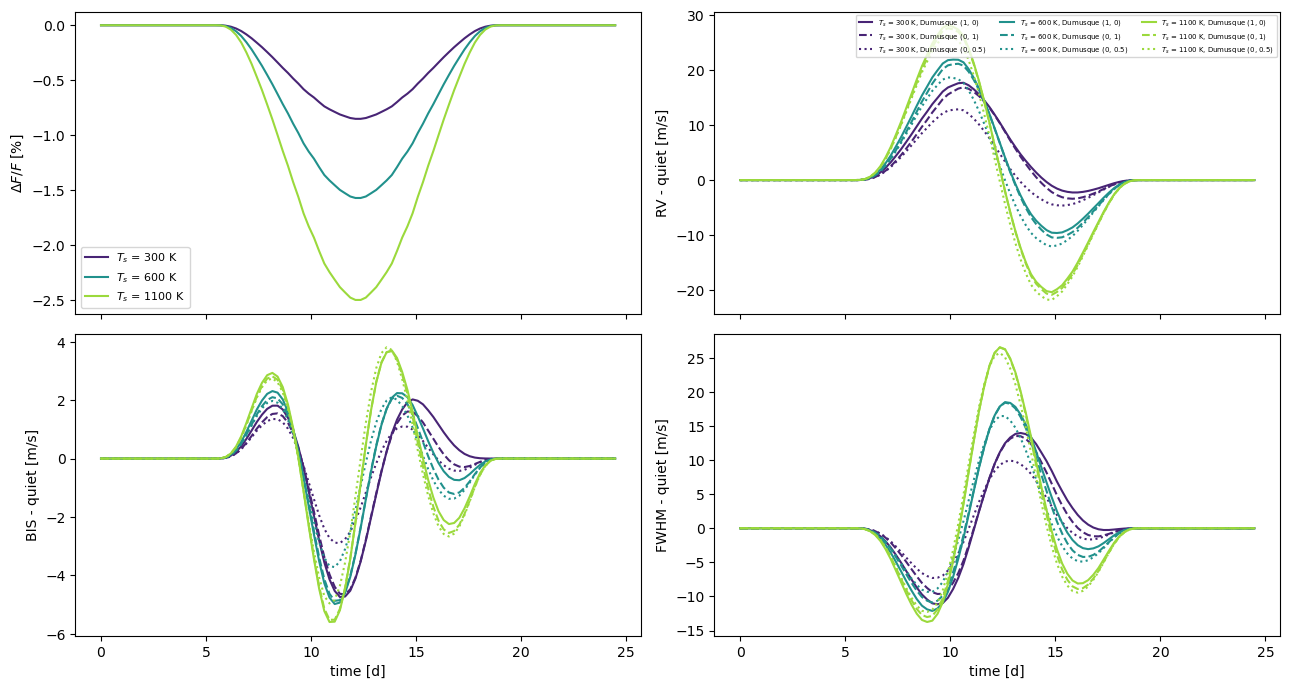

In [39]:
colors = dict(zip(spot_dTs, plt.cm.viridis([0.1, 0.5, 0.85])))
styles = dict(zip(mu_scalings, ['-', '--', ':']))

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
ax = axes[0, 0]
for dT in spot_dTs:
    ax.plot(time, photometry[dT], color=colors[dT], label='$T_s$ = %d K' % dT)
ax.set_ylabel('$\\Delta F / F$ [%]')
ax.legend(fontsize=8)

for ax, key, label in ((axes[0, 1], 'rv', 'RV'), (axes[1, 0], 'bis', 'BIS'), (axes[1, 1], 'fwhm', 'FWHM')):
    for dT in spot_dTs:
        for name in mu_scalings:
            ax.plot(time, ccf[dT, name][key], styles[name], color=colors[dT],
                    label='$T_s$ = %d K, %s' % (dT, name))
    ax.set_ylabel('%s - quiet [m/s]' % label)
axes[0, 1].legend(ncol=3,fontsize=5)
for ax in axes[1]:
    ax.set_xlabel('time [d]')
plt.tight_layout()
plt.show()

## Bisector vs $\mu$

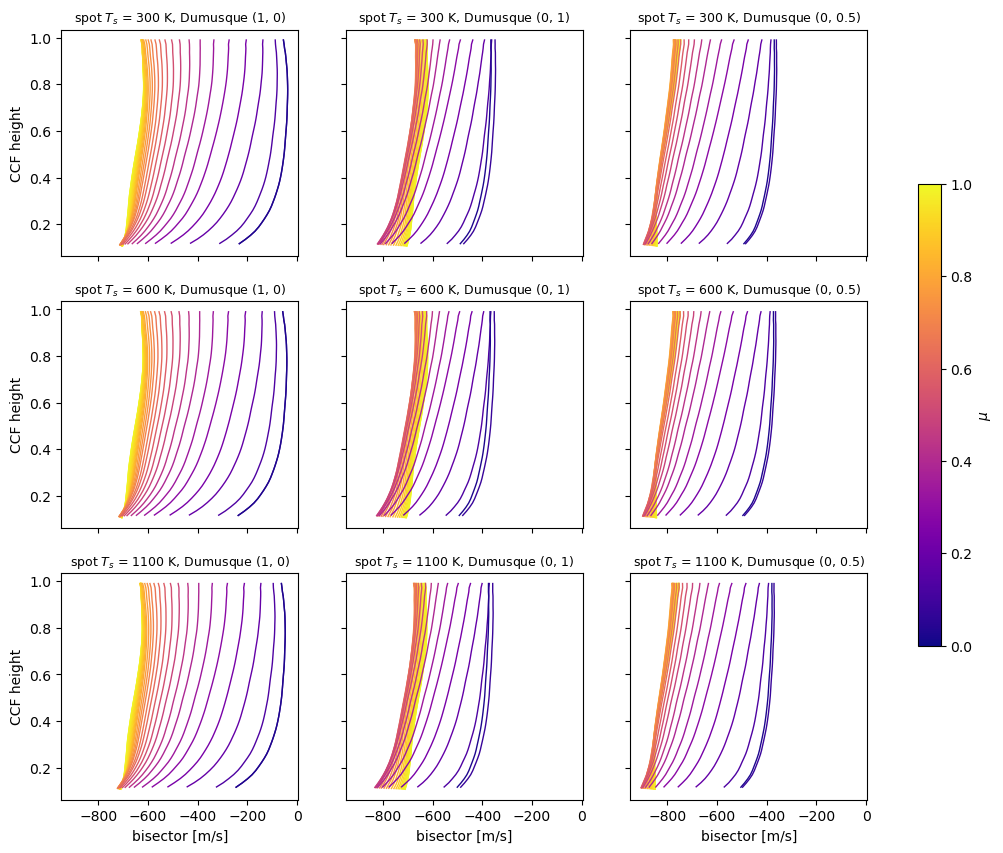

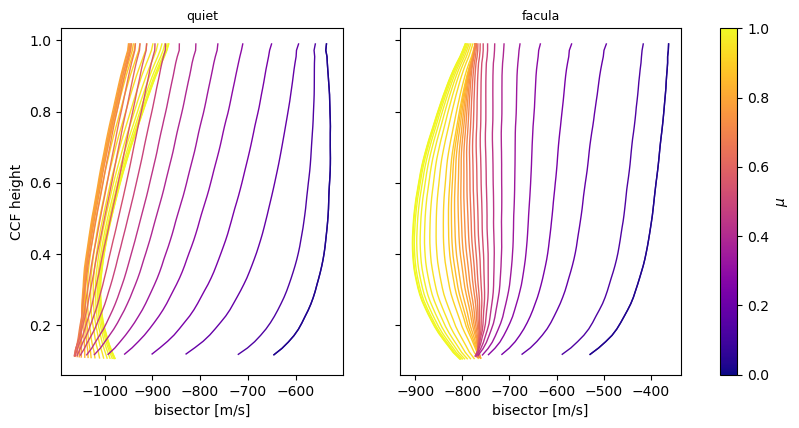

In [40]:
mu_norm = plt.Normalize(0, 1)
mu_cmap = plt.cm.plasma


def plot_bisectors(ax, bis, title):
    for mu, (xbis, ybis) in zip(amu_ring, bis):
        ax.plot(xbis, ybis, color=mu_cmap(mu_norm(mu)), lw=1)
    ax.set_title(title, fontsize=9)


fig, axes = plt.subplots(len(spot_dTs), len(mu_scalings), figsize=(13, 10), sharex=True, sharey=True)
for i, dT in enumerate(spot_dTs):
    for j, name in enumerate(mu_scalings):
        plot_bisectors(axes[i, j], bisectors[dT, name], 'spot $T_s$ = %d K, %s' % (dT, name))
for ax in axes[-1]:
    ax.set_xlabel('bisector [m/s]')
for ax in axes[:, 0]:
    ax.set_ylabel('CCF height')
fig.colorbar(plt.cm.ScalarMappable(norm=mu_norm, cmap=mu_cmap), ax=axes, label='$\\mu$', shrink=0.6)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, key in zip(axes, ('quiet', 'facula')):
    plot_bisectors(ax, bisectors[key], key)
    ax.set_xlabel('bisector [m/s]')
axes[0].set_ylabel('CCF height')
fig.colorbar(plt.cm.ScalarMappable(norm=mu_norm, cmap=mu_cmap), ax=axes, label='$\\mu$')
plt.show()

## Bisector relative to quiet

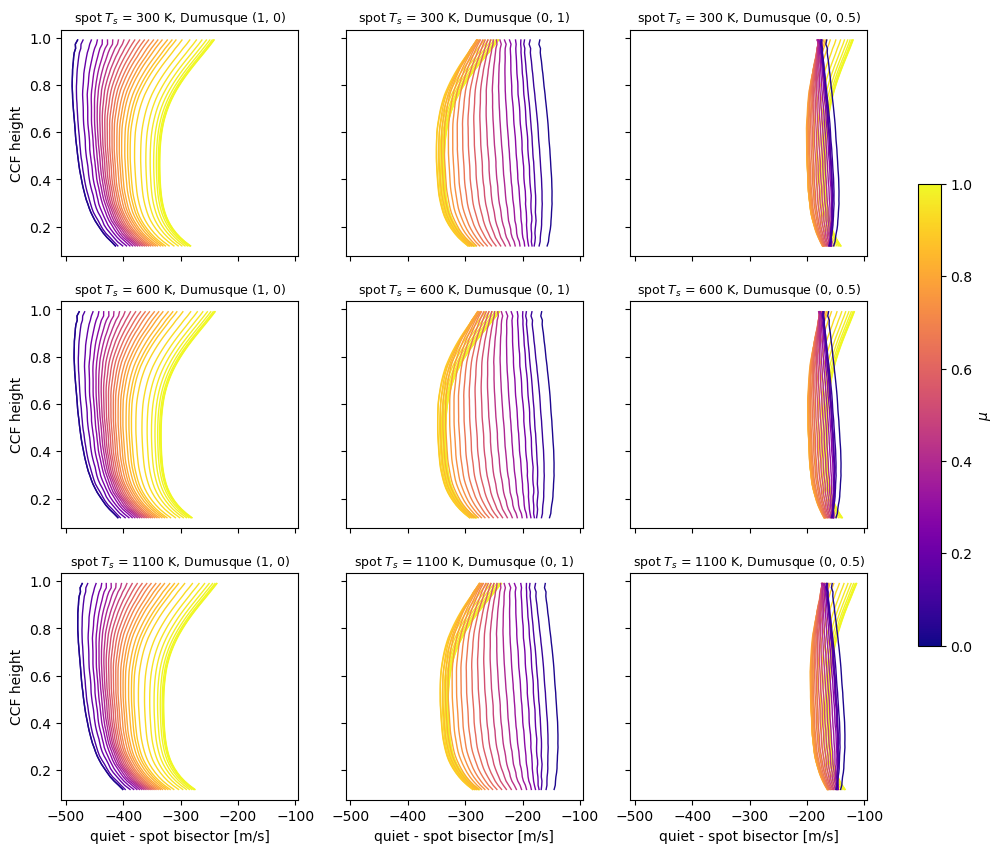

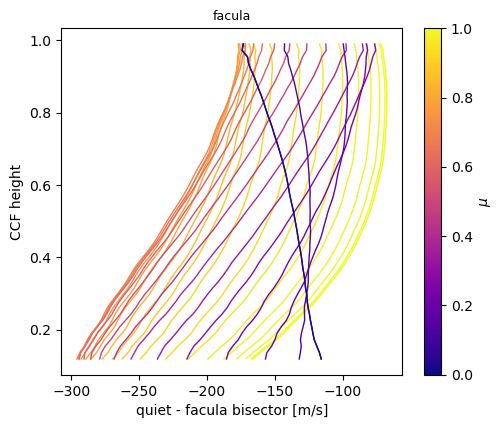

In [41]:
bis_heights = np.linspace(max(b[:, 1, 0].max() for b in bisectors.values()), 0.99, 50)


def relative_to_quiet(bis):
    out = np.empty((len(bis), 2, len(bis_heights)))
    for i, ((xq, yq), (x, y)) in enumerate(zip(bisectors['quiet'], bis)):
        out[i] = np.interp(bis_heights, yq, xq) - np.interp(bis_heights, y, x), bis_heights
    return out


fig, axes = plt.subplots(len(spot_dTs), len(mu_scalings), figsize=(13, 10), sharex=True, sharey=True)
for i, dT in enumerate(spot_dTs):
    for j, name in enumerate(mu_scalings):
        plot_bisectors(axes[i, j], relative_to_quiet(bisectors[dT, name]), 'spot $T_s$ = %d K, %s' % (dT, name))
for ax in axes[-1]:
    ax.set_xlabel('quiet - spot bisector [m/s]')
for ax in axes[:, 0]:
    ax.set_ylabel('CCF height')
fig.colorbar(plt.cm.ScalarMappable(norm=mu_norm, cmap=mu_cmap), ax=axes, label='$\\mu$', shrink=0.6)
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
plot_bisectors(ax, relative_to_quiet(bisectors['facula']), 'facula')
ax.set_xlabel('quiet - facula bisector [m/s]')
ax.set_ylabel('CCF height')
fig.colorbar(plt.cm.ScalarMappable(norm=mu_norm, cmap=mu_cmap), ax=ax, label='$\\mu$')
plt.show()

## Dumusque $\mu$ scaling from the facula

degree 1: f(mu) = [0.642 0.358] (increasing powers), rms 34.9 m/s
degree 3: f(mu) = [  1.571  -4.512  17.404 -13.463] (increasing powers), rms 5.1 m/s


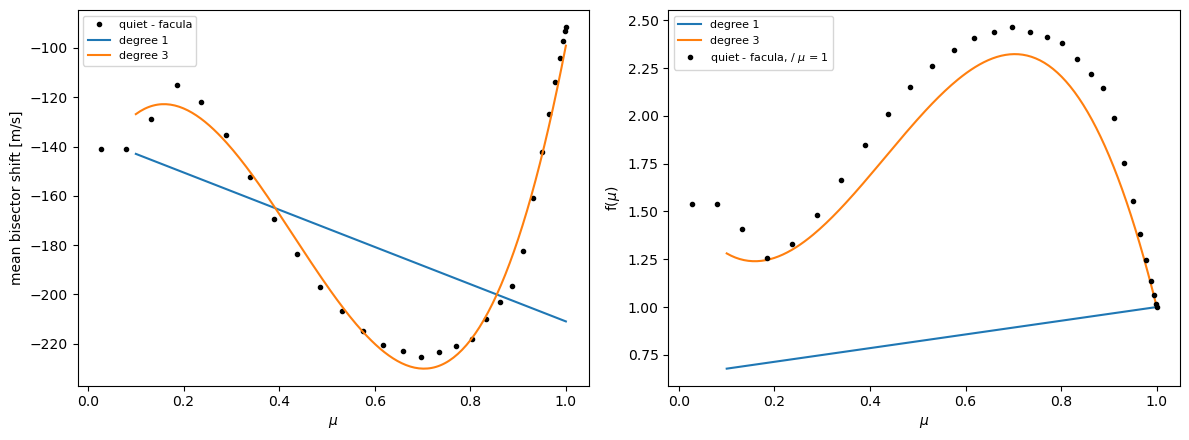

In [46]:
facula_shift = relative_to_quiet(bisectors['facula'])[:, 0].mean(1)      # quiet - facula, mean over the heights [m/s]
mu_fit = np.linspace(ccf_fac.limb_lim, 1, 200)                            # uniform in mu, without the extrapolated limb
shift_fit = np.interp(mu_fit, amu_ring[::-1], facula_shift[::-1])

facula_mu_scalings = {}                # degree -> (amplitude [m/s], f(mu) with f(1) = 1)
for deg in (1, 3):
    M = np.vstack([(mu_fit - 1)**k for k in range(deg + 1)]).T
    coef = np.linalg.lstsq(M, shift_fit, rcond=None)[0]
    f = np.polynomial.Polynomial(coef / coef[0])(np.polynomial.Polynomial([-1, 1]))
    facula_mu_scalings[deg] = (coef[0], f)
    print('degree %d: f(mu) = %s (increasing powers), rms %.1f m/s' % (deg, np.round(f.coef, 3), np.std(shift_fit - coef[0] * f(mu_fit))))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(amu_ring, facula_shift, 'k.', label='quiet - facula')
for deg, (c, f) in facula_mu_scalings.items():
    axes[0].plot(mu_fit, c * f(mu_fit), label='degree %d' % deg)
    axes[1].plot(mu_fit, f(mu_fit), label='degree %d' % deg)
axes[1].plot(amu_ring, facula_shift / facula_shift[0], 'k.', label='quiet - facula, / $\\mu$ = 1')
axes[0].set_ylabel('mean bisector shift [m/s]')
axes[1].set_ylabel('f($\\mu$)')
for ax in axes:
    ax.set_xlabel('$\\mu$')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Facula transit (same filling factor)

In [43]:
facula = [active_region('fc', 10, 90, 180)]     # same size and position as the spot

ss = StarSim(time, N_rings_phot, inclination=inclination, rotation_period=rotation_period,
             differential_rotation=differential_rotation, active_regions_map=facula, mode=['photometry'],
             stellar_radius=stellar_radius,
             flux_grid_qp=phot_quiet.grid, flux_grid_sp=phot_quiet.grid, flux_grid_fc=phot_fc.grid)
ss.generate_timeseries(verbose=False)
photometry_fc = 100 * (ss.flux_var / phot_quiet.total_brightness - 1)

ss = StarSim(time, N_rings_ccf, inclination=inclination, rotation_period=rotation_period,
             differential_rotation=differential_rotation, active_regions_map=facula, mode=['ccf'],
             stellar_radius=stellar_radius, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_quiet, ccf_grid_fc=ccf_fac)
ss.generate_timeseries(verbose=False)
assert ss.ff_fc[0] == 0
assert np.allclose(ss.ff_fc, ccf[spot_dTs[0], 'Dumusque (1, 0)']['ff_sp'])
ccf_fc = {'ff_fc': ss.ff_fc.copy(),
          'rv': ss.rv_var - ss.rv_var[0],
          'fwhm': ss.fwhm_var - ss.fwhm_var[0],
          'bis': ss.bis_var - ss.bis_var[0]}


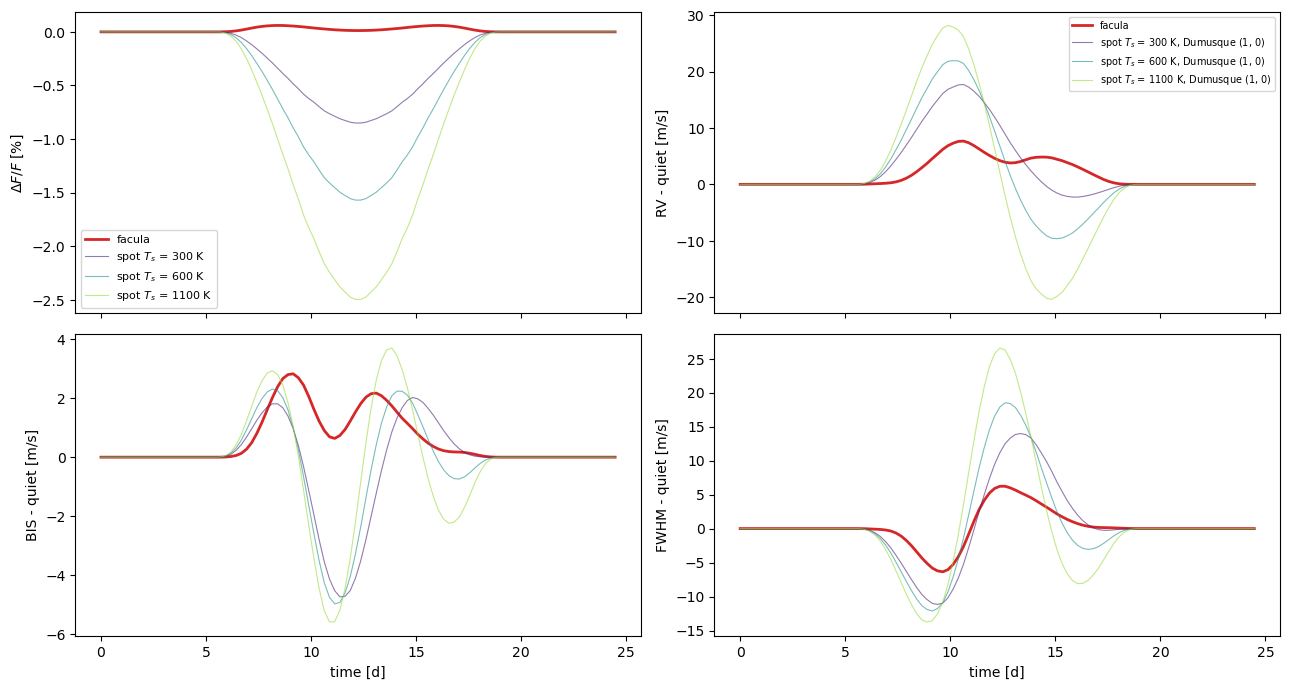

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
ax = axes[0, 0]
ax.plot(time, photometry_fc, 'C3', lw=2, label='facula')
for dT in spot_dTs:
    ax.plot(time, photometry[dT], color=colors[dT], lw=0.8, alpha=0.6, label='spot $T_s$ = %d K' % dT)
ax.set_ylabel('$\\Delta F / F$ [%]')
ax.legend(fontsize=8)

for ax, key, label in ((axes[0, 1], 'rv', 'RV'), (axes[1, 0], 'bis', 'BIS'), (axes[1, 1], 'fwhm', 'FWHM')):
    ax.plot(time, ccf_fc[key], 'C3', lw=2, label='facula')
    for dT in spot_dTs:
        ax.plot(time, ccf[dT, 'Dumusque (1, 0)'][key], color=colors[dT], lw=0.8, alpha=0.6,
                label='spot $T_s$ = %d K, Dumusque (1, 0)' % dT)
    ax.set_ylabel('%s - quiet [m/s]' % label)
axes[0, 1].legend(fontsize=7)
for ax in axes[1]:
    ax.set_xlabel('time [d]')
plt.tight_layout()
plt.show()


In [45]:
print('%-8s %10s %10s %10s %10s' % ('', 'dF/F [%]', 'RV [m/s]', 'BIS [m/s]', 'FWHM [m/s]'))
print('%-8s %10.4f %10.3f %10.3f %10.3f' % ('facula', np.ptp(photometry_fc), np.ptp(ccf_fc['rv']),
                                          np.ptp(ccf_fc['bis']), np.ptp(ccf_fc['fwhm'])))


           dF/F [%]   RV [m/s]  BIS [m/s] FWHM [m/s]
facula       0.0601      7.672      2.831     12.592
